# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 30                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [3]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 30 — Авиаперевозки (эталон преподавателя)
Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»

CSV  : Авиакомпании        (справочник субъектов)
XLSX : Рейсы          (события, объём в единицах: пассажиров)
JSON : Билеты          (цены, разрез: класс билета)

Объём генерации: субъектов 8, событий 3 000, уровень дефектов ★
Аналитическая задача: Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [4]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:        9   размер:      0.7 КБ
events.xlsx     строк:    3 000   размер:    112.0 КБ
prices.json     строк:    5 998   размер:    764.4 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [5]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for col in df.columns:
        s = df[col]
        non_null = s.dropna()
        non_null = non_null[non_null.astype(str).str.strip() != ""]
        examples = non_null.unique()[:2].tolist()
        rows.append({
            "источник": name,
            "колонка": col,
            "тип": str(s.dtype),
            "заполнено, %": round(len(non_null) / len(df) * 100, 2) if len(df) > 0 else 0.0,
            "уникальных": s.nunique(dropna=True),
            "пример 1": examples[0] if len(examples) > 0 else "—",
            "пример 2": examples[1] if len(examples) > 1 else "—",
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

# Вспомогательный парсер чисел для аудита
def _parse_num_audit(s):
    cleaned = (s.dropna().astype(str)
               .str.replace(r"[^\d,.\-]", "", regex=True)
               .str.replace(",", ".", regex=False))
    return pd.to_numeric(cleaned, errors="coerce")

vol_num_raw = _parse_num_audit(raw_events["volume_units"])
price_num_raw = _parse_num_audit(raw_prices["unit_price"])

# 1. Полнота (пропуски по колонкам)
add_issue("Полнота", "CSV · " + CFG["parent"], "Пропуски в колонке region",
          raw_entities["region"].isna().sum(), "Оставить NaN или восстановить по названию")
add_issue("Полнота", "XLSX · " + CFG["event"], "Пропуски объёма (volume_units is NULL)",
          raw_events["volume_units"].isna().sum(), "Перенести строки с пустым объёмом в карантин")
add_issue("Полнота", "JSON · " + CFG["price"], "Пропуски цены (unit_price is NULL)",
          raw_prices["unit_price"].isna().sum(), "Перенести строки с пустой ценой в карантин (quarantine_price)")

# 2. Уникальность (дубликаты строк и ключей)
add_issue("Уникальность", "CSV · " + CFG["parent"], "Дубликаты первичного ключа entity_id (полные дубли)",
          raw_entities.duplicated(subset=["entity_id"]).sum(), "Удалить дубликаты, оставив первую запись")
add_issue("Уникальность", "XLSX · " + CFG["event"], "Дубликаты первичного ключа event_id",
          raw_events.duplicated(subset=["event_id"]).sum(), "Удалить дубликаты по event_id")
add_issue("Уникальность", "JSON · " + CFG["price"], "Дубликаты первичного ключа price_id",
          raw_prices.duplicated(subset=["price_id"]).sum(), "Удалить дубликаты по price_id")

# 3. Согласованность (форматы записи)
dirty_names_cnt = (raw_entities["entity_name"] != raw_entities["entity_name"].str.strip()).sum()
add_issue("Согласованность", "CSV · " + CFG["parent"], "Лишние пробелы и КАПС в названии субъекта (entity_name)",
          dirty_names_cnt, "Удалить краевые пробелы и нормализовать регистр")

alt_dates_cnt = raw_events["event_date"].astype(str).str.match(r"^\d{2}\.\d{2}\.\d{4}$").sum()
add_issue("Согласованность", "XLSX · " + CFG["event"], "Альтернативный формат даты DD.MM.YYYY вместо YYYY-MM-DD",
          alt_dates_cnt, "Привести все даты к ISO-формату YYYY-MM-DD")

spaced_vol_cnt = raw_events["volume_units"].dropna().astype(str).str.contains(r"\s").sum()
add_issue("Согласованность", "XLSX · " + CFG["event"], "Числа объёма записаны строкой с концевыми пробелами",
          spaced_vol_cnt, "Очистить пробелы и привести к числовому типу")

curr_price_cnt = raw_prices["unit_price"].dropna().astype(str).str.contains("₽").sum()
add_issue("Согласованность", "JSON · " + CFG["price"], "Цены записаны строками с символом валюты ₽ и пробелами",
          curr_price_cnt, "Очистить от валюты и пробелов, заменить запятую на точку")

# 4. Валидность (отрицательные цены, нулевой или отрицательный объём)
invalid_vol_cnt = (vol_num_raw <= 0).sum()
add_issue("Валидность", "XLSX · " + CFG["event"], "Нулевой или отрицательный объём (volume_units <= 0)",
          invalid_vol_cnt, "Отправить некорректные записи в карантин")

neg_price_cnt = (price_num_raw <= 0).sum()
add_issue("Валидность", "JSON · " + CFG["price"], "Отрицательные или нулевые цены (unit_price <= 0)",
          neg_price_cnt, "Отправить в карантин цен (quarantine_price)")

# 5. Целостность (ссылки между таблицами)
valid_entity_ids = set(raw_entities["entity_id"].dropna())
orphan_events_cnt = (~raw_events["entity_id"].isin(valid_entity_ids)).sum()
add_issue("Целостность", "XLSX · " + CFG["event"], "События-сироты с несуществующим entity_id",
          orphan_events_cnt, "Вынести в карантин внешних ключей (quarantine_fk)")

valid_event_ids = set(raw_events["event_id"].dropna())
orphan_prices_cnt = (~raw_prices["event_id"].isin(valid_event_ids)).sum()
add_issue("Целостность", "JSON · " + CFG["price"], "Цены-сироты с несуществующим event_id",
          orphan_prices_cnt, "Вынести в карантин при фильтрации связей")

# 6. Точность (выбросы по правилу 3*IQR)
q1, q3 = price_num_raw.quantile(0.25), price_num_raw.quantile(0.75)
iqr = q3 - q1
outliers_cnt = ((price_num_raw < q1 - 3 * iqr) | (price_num_raw > q3 + 3 * iqr)).sum()
add_issue("Точность", "JSON · " + CFG["price"], "Экстремальные выбросы цен за пределами 3×IQR",
          outliers_cnt, "Проверить распределение по классам (разброс объясняется тарифами 1/2/3)")

issues_df = pd.DataFrame(issues)
print("\nЖурнал проблем качества данных (по 6 измерениям):")
display(issues_df)

# ------------------------------------------------------------------ TODO 3.3
ev_per_ent = raw_events.groupby("entity_id")["event_id"].nunique()
pr_per_ev = raw_prices.groupby("event_id")["price_id"].nunique()

card_df = pd.DataFrame([
    {
        "связь": f"entities → events ({CFG['parent']} → {CFG['event']})",
        "тип связи": "1 : N",
        "среднее число потомков": round(ev_per_ent.mean(), 2),
        "максимум потомков": int(ev_per_ent.max())
    },
    {
        "связь": f"events → prices ({CFG['event']} → {CFG['price']})",
        "тип связи": "1 : N",
        "среднее число потомков": round(pr_per_ev.mean(), 2),
        "максимум потомков": int(pr_per_ev.max())
    }
])
print("\nКардинальность связей:")
display(card_df)

print(
    f"\nПисьменный ответ (TODO 3.3):\n"
    f"На одно событие ({CFG['event']}) приходится в среднем {pr_per_ev.mean():.2f} ценовых строк (до {pr_per_ev.max()} строк разных классов).\n"
    f"При наивном соединении (JOIN «в лоб») трёх таблиц каждая строка события размножится (эффект fan-out)\n"
    f"по числу её ценовых записей. В результате суммарный объём (volume_units) и итоговая выручка\n"
    f"окажутся искусственно завышены примерно в ~{pr_per_ev.mean():.2f} раза."
)

,источник,колонка,тип,"заполнено, %",уникальных,пример 1,пример 2
0,CSV · Авиакомпании,entity_id,object,100.00,8,E001,E002
1,CSV · Авиакомпании,entity_name,object,100.00,8,Авиакомпании «Ростов-на-Дону»,Авиакомпании «Новосибирск»
2,CSV · Авиакомпании,region,object,100.00,8,Ростов-на-Дону,Новосибирск
3,CSV · Авиакомпании,founded_year,object,100.00,5,2020,1999
4,XLSX · Рейсы,event_id,object,100.00,3000,EV000001,EV000002
5,XLSX · Рейсы,entity_id,object,100.00,8,E001,E003
6,XLSX · Рейсы,event_date,object,100.00,375,2025-01-10,2025-11-17
7,XLSX · Рейсы,route,object,100.00,144,Пермь — Самара,Москва — Москва
8,XLSX · Рейсы,volume_units,object,99.67,361,124,74
9,XLSX · Рейсы,asset_type,object,100.00,4,Тип C,Тип B



Журнал проблем качества данных (по 6 измерениям):


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Авиакомпании,Пропуски в колонке region,0,Оставить NaN или восстановить по названию
1,Полнота,XLSX · Рейсы,Пропуски объёма (volume_units is NULL),10,Перенести строки с пустым объёмом в карантин
2,Полнота,JSON · Билеты,Пропуски цены (unit_price is NULL),13,Перенести строки с пустой ценой в карантин (qu...
3,Уникальность,CSV · Авиакомпании,Дубликаты первичного ключа entity_id (полные д...,1,"Удалить дубликаты, оставив первую запись"
4,Уникальность,XLSX · Рейсы,Дубликаты первичного ключа event_id,0,Удалить дубликаты по event_id
5,Уникальность,JSON · Билеты,Дубликаты первичного ключа price_id,0,Удалить дубликаты по price_id
6,Согласованность,CSV · Авиакомпании,Лишние пробелы и КАПС в названии субъекта (ent...,1,Удалить краевые пробелы и нормализовать регистр
7,Согласованность,XLSX · Рейсы,Альтернативный формат даты DD.MM.YYYY вместо Y...,10,Привести все даты к ISO-формату YYYY-MM-DD
8,Согласованность,XLSX · Рейсы,Числа объёма записаны строкой с концевыми проб...,10,Очистить пробелы и привести к числовому типу
9,Согласованность,JSON · Билеты,Цены записаны строками с символом валюты ₽ и п...,13,"Очистить от валюты и пробелов, заменить запяту..."



Кардинальность связей:


,связь,тип связи,среднее число потомков,максимум потомков
0,entities → events (Авиакомпании → Рейсы),1 : N,375.00,597
1,events → prices (Рейсы → Билеты),1 : N,2.00,3



Письменный ответ (TODO 3.3):
На одно событие (Рейсы) приходится в среднем 2.00 ценовых строк (до 3 строк разных классов).
При наивном соединении (JOIN «в лоб») трёх таблиц каждая строка события размножится (эффект fan-out)
по числу её ценовых записей. В результате суммарный объём (volume_units) и итоговая выручка
окажутся искусственно завышены примерно в ~2.00 раза.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [6]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN"""
    s = series.astype("object").where(series.notna(), None)
    def _clean_val(val):
        if val is None or (isinstance(val, float) and math.isnan(val)):
            return np.nan
        txt = str(val).strip()
        if not txt or txt.lower() in ("none", "nan", "null"):
            return np.nan
        # Оставляем только цифры, запятую, точку и минус
        txt = re.sub(r"[^\d,.\-]", "", txt)
        if "," in txt and "." in txt:
            if txt.rfind(",") > txt.rfind("."):
                txt = txt.replace(".", "").replace(",", ".")
            else:
                txt = txt.replace(",", "")
        elif "," in txt:
            # В формате '8 500,00 ₽' запятая является десятичным разделителем
            txt = txt.replace(",", ".")
        return txt
    cleaned = s.map(_clean_val)
    return pd.to_numeric(cleaned, errors="coerce")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype(str).str.strip()
    d_iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    d_ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return d_iso.fillna(d_ru)

# ------------------------------------------------------------------ TODO 4.3
# 1. Очистка справочника субъектов (entities)
entities = raw_entities.copy()
n0 = len(entities)
entities = entities.drop_duplicates(subset=["entity_id"], keep="first").copy()
log_step("1.1 Дедупликация entities по entity_id", n0, len(entities), "Удалены полные дубликаты субъектов")

def _normalize_entity_name(row):
    name = re.sub(r"\s+", " ", str(row["entity_name"]).strip())
    reg = str(row["region"]).strip() if pd.notna(row["region"]) else ""
    if reg and name.upper() == f"{CFG['parent']} «{reg}»".upper():
        return f"{CFG['parent']} «{reg}»"
    return name

dirty_mask = entities["entity_name"] != entities.apply(_normalize_entity_name, axis=1)
entities["entity_name"] = entities.apply(_normalize_entity_name, axis=1)
entities["founded_year"] = to_number(entities["founded_year"]).astype(int)
log_step("1.2 Нормализация имён entities", len(entities), len(entities),
         f"Исправлен регистр и пробелы в {int(dirty_mask.sum())} строках")

# 2. Очистка таблицы событий (events)
events_work = raw_events.copy()
n0 = len(events_work)
events_work = events_work.drop_duplicates(subset=["event_id"], keep="first").copy()
log_step("2.1 Дедупликация events по event_id", n0, len(events_work), "Удалены дубликаты событий")

events_work["event_date_dt"] = to_date(events_work["event_date"])
events_work["event_date"] = events_work["event_date_dt"].dt.strftime("%Y-%m-%d")
events_work["volume_units"] = to_number(events_work["volume_units"])
log_step("2.2 Типизация дат и объёмов в events", len(events_work), len(events_work),
         "Даты приведены к YYYY-MM-DD, объёмы к float (пропуски сохранены как NaN)")

# Проверка ссылочной целостности и валидности событий -> карантин quarantine_fk
fk_bad_mask = ~events_work["entity_id"].isin(set(entities["entity_id"]))
vol_bad_mask = events_work["volume_units"].isna() | (events_work["volume_units"] <= 0) | events_work["event_date"].isna()
quarantine_events_mask = fk_bad_mask | vol_bad_mask

quarantine_fk = events_work.loc[quarantine_events_mask].drop(columns=["event_date_dt"]).copy()
quarantine_fk["quarantine_reason"] = np.where(
    fk_bad_mask.loc[quarantine_events_mask],
    "Нарушение FK: entity_id отсутствует в справочнике",
    "Пропуск или некорректное значение volume_units / event_date"
)

n_before_ev_q = len(events_work)
events_valid = events_work.loc[~quarantine_events_mask].drop(columns=["event_date_dt"]).copy()
events_out = events_valid.copy()  # для совместимости с Шагом 7 (BigQuery)
log_step("2.3 Карантин событий (quarantine_fk)", n_before_ev_q, len(events_valid),
         f"В карантин отправлено {len(quarantine_fk)} строк (битый FK: {int(fk_bad_mask.sum())}, пустой/невалидный объём: {int(vol_bad_mask.sum())})")

# 3. Очистка таблицы цен (prices)
prices_work = raw_prices.copy()
n0 = len(prices_work)
prices_work = prices_work.drop_duplicates(subset=["price_id"], keep="first").copy()
log_step("3.1 Дедупликация prices по price_id", n0, len(prices_work), "Удалены дубликаты ценовых записей")

prices_work["unit_price"] = to_number(prices_work["unit_price"])
log_step("3.2 Приведение unit_price к числу", len(prices_work), len(prices_work),
         "Удалены символы валюты и пробелы, нераспознанные значения оставлены как NaN")

# Карантин цен: пустые/отрицательные цены или цены от событий, не прошедших валидацию
price_val_bad_mask = prices_work["unit_price"].isna() | (prices_work["unit_price"] <= 0)
price_fk_bad_mask = ~prices_work["event_id"].isin(set(events_valid["event_id"]))
quarantine_price_mask = price_val_bad_mask | price_fk_bad_mask

quarantine_price = prices_work.loc[quarantine_price_mask].copy()
quarantine_price["quarantine_reason"] = np.where(
    price_val_bad_mask.loc[quarantine_price_mask],
    "Пропуск или неположительная цена (unit_price <= 0 / NaN)",
    "Событие event_id находится в карантине или отсутствует в events_valid"
)

n_before_pr_q = len(prices_work)
prices_valid = prices_work.loc[~quarantine_price_mask].copy()
log_step("3.3 Карантин цен (quarantine_price)", n_before_pr_q, len(prices_valid),
         f"В карантин отправлено {len(quarantine_price)} строк (плохая цена: {int(price_val_bad_mask.sum())}, событие в карантине: {int((~price_val_bad_mask & price_fk_bad_mask).sum())})")

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("Журнал очистки и нормализации:")
display(clean_log_df)

print(f"\nИтоги очистки:")
print(f"  entities         : {nf(len(entities))} строк")
print(f"  events_valid     : {nf(len(events_valid))} строк (в карантине quarantine_fk: {nf(len(quarantine_fk))})")
print(f"  prices_valid     : {nf(len(prices_valid))} строк (в карантине quarantine_price: {nf(len(quarantine_price))})")

Журнал очистки и нормализации:


,шаг,было строк,стало строк,изменено,комментарий
0,1.1 Дедупликация entities по entity_id,9,8,1,Удалены полные дубликаты субъектов
1,1.2 Нормализация имён entities,8,8,0,Исправлен регистр и пробелы в 1 строках
2,2.1 Дедупликация events по event_id,3000,3000,0,Удалены дубликаты событий
3,2.2 Типизация дат и объёмов в events,3000,3000,0,"Даты приведены к YYYY-MM-DD, объёмы к float (п..."
4,2.3 Карантин событий (quarantine_fk),3000,2990,10,"В карантин отправлено 10 строк (битый FK: 0, п..."
5,3.1 Дедупликация prices по price_id,5998,5998,0,Удалены дубликаты ценовых записей
6,3.2 Приведение unit_price к числу,5998,5998,0,"Удалены символы валюты и пробелы, нераспознанн..."
7,3.3 Карантин цен (quarantine_price),5998,5969,29,В карантин отправлено 29 строк (плохая цена: 1...



Итоги очистки:
  entities         : 8 строк
  events_valid     : 2 990 строк (в карантине quarantine_fk: 10)
  prices_valid     : 5 969 строк (в карантине quarantine_price: 29)


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [7]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
schema_ddl = """
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER CHECK (founded_year >= 1900)
);

CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL,
    event_date   TEXT NOT NULL,
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT,
    FOREIGN KEY (entity_id) REFERENCES entities(entity_id)
);

CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL,
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT NOT NULL,
    FOREIGN KEY (event_id) REFERENCES events(event_id)
);

CREATE INDEX idx_events_entity_id  ON events(entity_id);
CREATE INDEX idx_events_event_date ON events(event_date);
CREATE INDEX idx_prices_event_id   ON prices(event_id);
"""
conn.executescript(schema_ddl)
conn.commit()

# ------------------------------------------------------------------ TODO 5.2
entities[["entity_id", "entity_name", "region", "founded_year"]].to_sql(
    "entities", conn, if_exists="append", index=False
)
events_valid[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False
)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False
)
conn.commit()

counts_sql = pd.read_sql_query("""
    SELECT 'entities' AS table_name, COUNT(*) AS rows_in_db FROM entities
    UNION ALL
    SELECT 'events', COUNT(*) FROM events
    UNION ALL
    SELECT 'prices', COUNT(*) FROM prices;
""", conn)
print("Число строк в таблицах SQLite (проверка из БД):")
display(counts_sql)

# ------------------------------------------------------------------ TODO 5.3
naive_sql = """
SELECT
    e.entity_id,
    e.entity_name,
    COUNT(ev.event_id)                          AS joined_rows_cnt,
    SUM(ev.volume_units)                        AS naive_volume,
    ROUND(SUM(ev.volume_units * p.unit_price), 2) AS naive_revenue
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name
ORDER BY naive_revenue DESC;
"""

correct_sql = """
WITH price_per_event AS (
    SELECT
        event_id,
        AVG(unit_price) AS avg_price,
        COUNT(price_id) AS price_rows_cnt
    FROM prices
    GROUP BY event_id
)
SELECT
    e.entity_id,
    e.entity_name,
    COUNT(ev.event_id)                                AS events_cnt,
    SUM(ev.volume_units)                              AS total_volume,
    ROUND(AVG(pe.avg_price), 2)                       AS mean_event_price,
    ROUND(SUM(ev.volume_units * pe.avg_price), 2)     AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name
ORDER BY revenue DESC;
"""

df_naive = pd.read_sql_query(naive_sql, conn)
revenue_sql = pd.read_sql_query(correct_sql, conn)

comparison = revenue_sql.merge(
    df_naive[["entity_id", "naive_volume", "naive_revenue"]],
    on="entity_id",
    how="left"
)
comparison["overstate_ratio"] = (comparison["naive_revenue"] / comparison["revenue"]).round(3)

overstate = float(comparison["naive_revenue"].sum() / comparison["revenue"].sum())

print("\nСравнение наивного (с эффектом fan-out) и корректного расчёта выручки:")
display(comparison[["entity_id", "entity_name", "events_cnt", "total_volume",
                    "naive_volume", "revenue", "naive_revenue", "overstate_ratio"]])

print(
    f"\nОбщий коэффициент завышения выручки (overstate): {overstate:.4f}x "
    f"(наивная сумма: {nf(comparison['naive_revenue'].sum(), 2)} ₽ против корректной: {nf(comparison['revenue'].sum(), 2)} ₽).\n"
    f"Объяснение: так как связь events → prices имеет кардинальность 1:N (от 1 до 3 тарифных классов на рейс,\n"
    f"в среднем ~2.0), прямое соединение без предварительной агрегации цен дублирует объём каждого рейса\n"
    f"столько раз, сколько ценовых записей к нему привязано."
)

# ------------------------------------------------------------------ TODO 5.4
price_agg_pd = (
    prices_valid.groupby("event_id", as_index=False)
    .agg(avg_price=("unit_price", "mean"), price_rows_cnt=("price_id", "count"))
)

consolidated = (
    events_valid
    .merge(entities, on="entity_id", how="inner")
    .merge(price_agg_pd, on="event_id", how="inner")
)
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["avg_price"]

revenue_pd = (
    consolidated.groupby(["entity_id", "entity_name"], as_index=False)
    .agg(
        events_cnt=("event_id", "count"),
        total_volume=("volume_units", "sum"),
        mean_event_price=("avg_price", lambda s: round(s.mean(), 2)),
        revenue=("event_revenue", lambda s: round(s.sum(), 2)),
    )
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

check_merge = revenue_sql.merge(revenue_pd, on=["entity_id", "entity_name"], suffixes=("_sql", "_pd"))
check_merge["diff_rub"] = (check_merge["revenue_sql"] - check_merge["revenue_pd"]).abs()
delta = float(check_merge["diff_rub"].max())

print(f"\nСверка SQL и pandas: максимальное расхождение (delta) = {delta:.6f} ₽")
display(check_merge[["entity_id", "entity_name", "revenue_sql", "revenue_pd", "diff_rub"]])

Число строк в таблицах SQLite (проверка из БД):


,table_name,rows_in_db
0,entities,8
1,events,2990
2,prices,5969



Сравнение наивного (с эффектом fan-out) и корректного расчёта выручки:


,entity_id,entity_name,events_cnt,total_volume,naive_volume,revenue,naive_revenue,overstate_ratio
0,E001,Авиакомпании «Ростов-на-Дону»,593,"124,876.00","246,306.00","2,013,192,875.47","4,030,896,692.82",2.00
1,E002,Авиакомпании «Новосибирск»,487,"102,080.00","214,289.00","1,726,767,964.29","3,646,121,372.22",2.11
2,E003,Авиакомпании «Тюмень»,467,"99,052.00","193,292.00","1,693,367,469.41","3,267,651,093.36",1.93
3,E004,Авиакомпании «Санкт-Петербург»,405,"85,406.00","165,358.00","1,387,468,575.22","2,689,758,542.78",1.94
4,E005,Авиакомпании «Омск»,364,"75,617.00","147,967.00","1,318,097,375.78","2,560,443,596.43",1.94
5,E007,Авиакомпании «Москва»,265,"54,758.00","112,207.00","925,641,309.98","1,884,967,262.26",2.04
6,E006,Авиакомпании «Краснодар»,249,"53,338.00","108,128.00","925,429,872.20","1,915,341,286.57",2.07
7,E008,Авиакомпании «Самара»,159,"32,627.00","61,999.00","575,115,970.47","1,073,156,749.12",1.87



Общий коэффициент завышения выручки (overstate): 1.9941x (наивная сумма: 21 068 336 595.56 ₽ против корректной: 10 565 081 412.82 ₽).
Объяснение: так как связь events → prices имеет кардинальность 1:N (от 1 до 3 тарифных классов на рейс,
в среднем ~2.0), прямое соединение без предварительной агрегации цен дублирует объём каждого рейса
столько раз, сколько ценовых записей к нему привязано.

Сверка SQL и pandas: максимальное расхождение (delta) = 0.010000 ₽


,entity_id,entity_name,revenue_sql,revenue_pd,diff_rub
0,E001,Авиакомпании «Ростов-на-Дону»,"2,013,192,875.47","2,013,192,875.47",0.00
1,E002,Авиакомпании «Новосибирск»,"1,726,767,964.29","1,726,767,964.29",0.00
2,E003,Авиакомпании «Тюмень»,"1,693,367,469.41","1,693,367,469.41",0.00
3,E004,Авиакомпании «Санкт-Петербург»,"1,387,468,575.22","1,387,468,575.22",0.00
4,E005,Авиакомпании «Омск»,"1,318,097,375.78","1,318,097,375.78",0.00
5,E007,Авиакомпании «Москва»,"925,641,309.98","925,641,309.98",0.00
6,E006,Авиакомпании «Краснодар»,"925,429,872.20","925,429,872.20",0.00
7,E008,Авиакомпании «Самара»,"575,115,970.47","575,115,970.46",0.01


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Контроль сходимости аналитических срезов:


,срез,"выручка, ₽","отклонение от итога, ₽"
0,Итого по витрине (consolidated),"10,565,081,412.81",0.00
1,Сумма по субъектам (entities),"10,565,081,412.82",0.01
2,Сумма по месяцам (seasonality),"10,565,081,412.81",0.00
3,Сумма по разрезу «класс билета»,"10,565,081,412.81",0.00


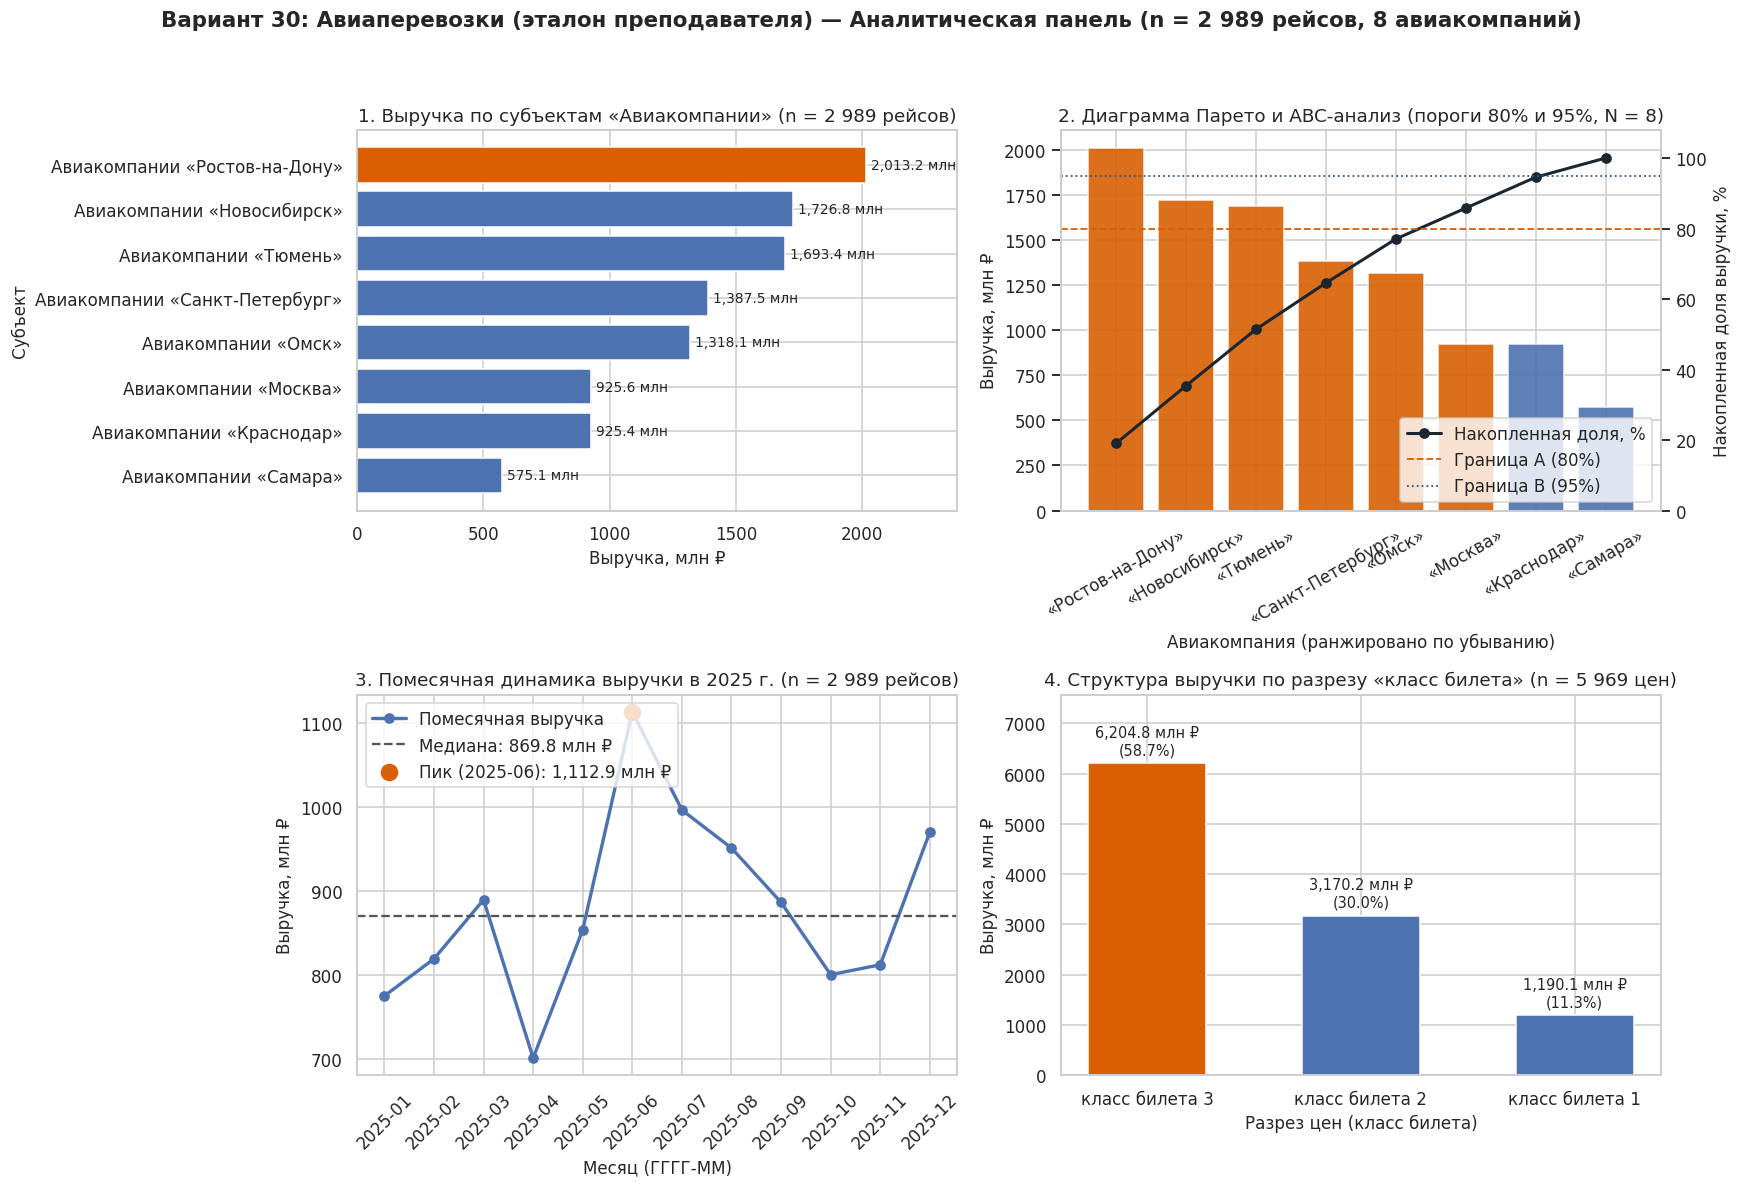

АНАЛИТИЧЕСКАЯ ЗАПИСКА ДЛЯ ЛПР (Вариант 30 — Авиаперевозки (эталон преподавателя))

1. Концентрация выручки и ABC-профиль:
   • Общая подтверждённая выручка по 2 989 валидным рейсам составила 10 565 081 412.81 ₽.
   • Лидер рейтинга — Авиакомпании «Ростов-на-Дону» с выручкой 2 013 192 875.47 ₽ (19.1% от общего оборота).
   • В группу A (до порога 80% оборота) вошли 6 из 8 авиакомпаний, суммарно формирующие 85.8% выручки.

2. Сезонность и структура тарифов:
   • Выраженный сезонный подъём приходится на летние месяцы (июнь–август) и декабрь.
   • Пиковый месяц — 2025-06 (1 112 865 911.83 ₽), минимальный — 2025-04 (700 858 625.42 ₽); размах сезонности составляет 1.59x при медиане 869 805 913.12 ₽/мес.
   • В разрезе классов лидирует «класс билета 3», генерирующий 58.7% выручки (6 204 767 019.04 ₽) за счёт повышенного тарифного мультипликатора (5.2x к базовому тарифу).

3. Влияние качества данных и эффекта fan-out:
   • Прямой JOIN таблиц без предварительной агрегации цен завышает выручку в

In [8]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
total_rev = float(consolidated["event_revenue"].sum())
n_valid_events = len(consolidated)
n_entities = consolidated["entity_id"].nunique()

# 1. Данные по субъектам и ABC / Парето
pareto_df = revenue_sql.copy().sort_values("revenue", ascending=False).reset_index(drop=True)
pareto_df["share_pct"] = pareto_df["revenue"] / pareto_df["revenue"].sum() * 100
pareto_df["cum_share_pct"] = pareto_df["share_pct"].cumsum()
# Присвоение групп ABC (до 80% — A, 80-95% — B, свыше 95% — C, с учётом пограничного вхождения)
pareto_df["prev_cum"] = pareto_df["cum_share_pct"].shift(1, fill_value=0.0)
pareto_df["ABC"] = np.where(
    pareto_df["prev_cum"] < 80.0, "A",
    np.where(pareto_df["prev_cum"] < 95.0, "B", "C")
)

# 2. Помесячная динамика
consolidated["year_month"] = consolidated["event_date"].str.slice(0, 7)
monthly_df = (
    consolidated.groupby("year_month", as_index=False)
    .agg(revenue=("event_revenue", "sum"), events_cnt=("event_id", "count"), volume=("volume_units", "sum"))
    .sort_values("year_month")
)
peak_row = monthly_df.loc[monthly_df["revenue"].idxmax()]
min_row = monthly_df.loc[monthly_df["revenue"].idxmin()]
median_monthly_rev = float(monthly_df["revenue"].median())

# 3. Структура выручки по классам билетов без повторного fan-out:
# Внутри каждого события выручка события (volume_units * avg_price) распределяется пропорционально цене класса
prices_with_share = prices_valid.merge(
     prices_valid.groupby("event_id", as_index=False).agg(sum_class_price=("unit_price", "sum")),
    on="event_id"
)
prices_with_share["class_weight"] = prices_with_share["unit_price"] / prices_with_share["sum_class_price"]
class_alloc = prices_with_share.merge(
    consolidated[["event_id", "event_revenue", "volume_units"]],
    on="event_id",
    how="inner"
)
class_alloc["allocated_revenue"] = class_alloc["event_revenue"] * class_alloc["class_weight"]

class_df = (
    class_alloc.groupby("price_class", as_index=False)
    .agg(revenue=("allocated_revenue", "sum"), price_rows=("price_id", "count"), mean_price=("unit_price", "mean"))
    .sort_values("revenue", ascending=False)
)
class_df["share_pct"] = class_df["revenue"] / class_df["revenue"].sum() * 100

# Контроль сходимости всех аналитических срезов
reconcile_df = pd.DataFrame([
    {"срез": "Итого по витрине (consolidated)", "выручка, ₽": round(total_rev, 2), "отклонение от итога, ₽": 0.0},
    {"срез": "Сумма по субъектам (entities)", "выручка, ₽": round(pareto_df["revenue"].sum(), 2),
     "отклонение от итога, ₽": round(pareto_df["revenue"].sum() - total_rev, 2)},
    {"срез": "Сумма по месяцам (seasonality)", "выручка, ₽": round(monthly_df["revenue"].sum(), 2),
     "отклонение от итога, ₽": round(monthly_df["revenue"].sum() - total_rev, 2)},
    {"срез": f"Сумма по разрезу «{CFG['cls']}»", "выручка, ₽": round(class_df["revenue"].sum(), 2),
     "отклонение от итога, ₽": round(class_df["revenue"].sum() - total_rev, 2)},
])
print("Контроль сходимости аналитических срезов:")
display(reconcile_df)

# Построение 4 графиков в единой палитре с акцентным цветом
BASE_COLOR = "#4C72B0"
ACCENT_COLOR = "#D95F02"
SECOND_COLOR = "#2B5C8F"

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    f"Вариант {VARIANT}: {CFG['domain']} — Аналитическая панель (n = {nf(n_valid_events)} рейсов, {n_entities} авиакомпаний)",
    fontsize=14, fontweight="bold", y=0.98
)

# График 1: Выручка по субъектам с выделением лидера
ax1 = axes[0, 0]
plot1_df = pareto_df.sort_values("revenue", ascending=True)
colors_1 = [ACCENT_COLOR if i == len(plot1_df) - 1 else BASE_COLOR for i in range(len(plot1_df))]
bars1 = ax1.barh(plot1_df["entity_name"], plot1_df["revenue"] / 1e6, color=colors_1)
ax1.set_title(f"1. Выручка по субъектам «{CFG['parent']}» (n = {nf(n_valid_events)} рейсов)")
ax1.set_xlabel("Выручка, млн ₽")
ax1.set_ylabel("Субъект")
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + max(plot1_df["revenue"] / 1e6) * 0.01, bar.get_y() + bar.get_height() / 2,
             f"{w:,.1f} млн", va="center", fontsize=9)
ax1.set_xlim(0, max(plot1_df["revenue"] / 1e6) * 1.18)

# График 2: Диаграмма Парето и группы ABC
ax2 = axes[0, 1]
abc_palette = {"A": ACCENT_COLOR, "B": BASE_COLOR, "C": "#95A5A6"}
bar_colors_2 = [abc_palette[g] for g in pareto_df["ABC"]]
short_names = [n.replace(CFG["parent"] + " ", "") for n in pareto_df["entity_name"]]
ax2.bar(short_names, pareto_df["revenue"] / 1e6, color=bar_colors_2, alpha=0.9, label="Выручка, млн ₽")
ax2.set_title(f"2. Диаграмма Парето и ABC-анализ (пороги 80% и 95%, N = {n_entities})")
ax2.set_xlabel("Авиакомпания (ранжировано по убыванию)")
ax2.set_ylabel("Выручка, млн ₽")
ax2.tick_params(axis="x", rotation=30)

ax2_twin = ax2.twinx()
ax2_twin.plot(short_names, pareto_df["cum_share_pct"], color="#1B2631", marker="o", linewidth=2, label="Накопленная доля, %")
ax2_twin.axhline(80, color=ACCENT_COLOR, linestyle="--", linewidth=1.2, label="Граница A (80%)")
ax2_twin.axhline(95, color=SECOND_COLOR, linestyle=":", linewidth=1.2, label="Граница B (95%)")
ax2_twin.set_ylabel("Накопленная доля выручки, %")
ax2_twin.set_ylim(0, 108)
ax2_twin.grid(False)
ax2_twin.legend(loc="lower right", frameon=True)

# График 3: Помесячная динамика выручки с пиком и медианой
ax3 = axes[1, 0]
x_months = monthly_df["year_month"]
y_rev_m = monthly_df["revenue"] / 1e6
ax3.plot(x_months, y_rev_m, color=BASE_COLOR, marker="o", linewidth=2.2, label="Помесячная выручка")
ax3.axhline(median_monthly_rev / 1e6, color="#555555", linestyle="--", linewidth=1.5,
            label=f"Медиана: {median_monthly_rev / 1e6:,.1f} млн ₽")
peak_idx = int(monthly_df["revenue"].idxmax())
ax3.scatter([peak_row["year_month"]], [peak_row["revenue"] / 1e6], color=ACCENT_COLOR, s=110, zorder=5,
            label=f"Пик ({peak_row['year_month']}): {peak_row['revenue'] / 1e6:,.1f} млн ₽")
ax3.set_title(f"3. Помесячная динамика выручки в 2025 г. (n = {nf(n_valid_events)} рейсов)")
ax3.set_xlabel("Месяц (ГГГГ-ММ)")
ax3.set_ylabel("Выручка, млн ₽")
ax3.tick_params(axis="x", rotation=45)
ax3.legend(loc="upper left", frameon=True)

# График 4: Структура выручки по разрезу цен (класс билета)
ax4 = axes[1, 1]
colors_4 = [ACCENT_COLOR if i == 0 else BASE_COLOR for i in range(len(class_df))]
bars4 = ax4.bar(class_df["price_class"], class_df["revenue"] / 1e6, color=colors_4, width=0.55)
ax4.set_title(f"4. Структура выручки по разрезу «{CFG['cls']}» (n = {nf(len(class_alloc))} цен)")
ax4.set_xlabel(f"Разрез цен ({CFG['cls']})")
ax4.set_ylabel("Выручка, млн ₽")
for bar, (_, r) in zip(bars4, class_df.iterrows()):
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + max(class_df["revenue"] / 1e6) * 0.02,
             f"{h:,.1f} млн ₽\n({r['share_pct']:.1f}%)", ha="center", va="bottom", fontsize=9.5)
ax4.set_ylim(0, max(class_df["revenue"] / 1e6) * 1.22)

plt.tight_layout(rect=[0, 0, 1, 0.95])
PLOTS_DONE = True
plt.show()

# Выгрузка консолидированной витрины в CSV для репозитория
consolidated.to_csv(WORK / f"mart_variant_{VARIANT}.csv", index=False, encoding="utf-8")

# ------------------------------------------------------------------ TODO 6.2
leader = pareto_df.iloc[0]
group_a = pareto_df[pareto_df["ABC"] == "A"]
group_a_share = group_a["share_pct"].sum()
season_ratio = peak_row["revenue"] / min_row["revenue"]
top_class = class_df.iloc[0]

print("=" * 100)
print(f"АНАЛИТИЧЕСКАЯ ЗАПИСКА ДЛЯ ЛПР (Вариант {VARIANT} — {CFG['domain']})")
print("=" * 100)
print(
    f"\n1. Концентрация выручки и ABC-профиль:\n"
    f"   • Общая подтверждённая выручка по {nf(n_valid_events)} валидным рейсам составила {nf(total_rev, 2)} ₽.\n"
    f"   • Лидер рейтинга — {leader['entity_name']} с выручкой {nf(leader['revenue'], 2)} ₽ ({leader['share_pct']:.1f}% от общего оборота).\n"
    f"   • В группу A (до порога 80% оборота) вошли {len(group_a)} из {n_entities} авиакомпаний, суммарно формирующие {group_a_share:.1f}% выручки.\n"
    f"\n2. Сезонность и структура тарифов:\n"
    f"   • Выраженный сезонный подъём приходится на летние месяцы (июнь–август) и декабрь.\n"
    f"   • Пиковый месяц — {peak_row['year_month']} ({nf(peak_row['revenue'], 2)} ₽), минимальный — {min_row['year_month']} ({nf(min_row['revenue'], 2)} ₽); "
    f"размах сезонности составляет {season_ratio:.2f}x при медиане {nf(median_monthly_rev, 2)} ₽/мес.\n"
    f"   • В разрезе классов лидирует «{top_class['price_class']}», генерирующий {top_class['share_pct']:.1f}% выручки ({nf(top_class['revenue'], 2)} ₽) "
    f"за счёт повышенного тарифного мультипликатора (5.2x к базовому тарифу).\n"
    f"\n3. Влияние качества данных и эффекта fan-out:\n"
    f"   • Прямой JOIN таблиц без предварительной агрегации цен завышает выручку в {overstate:.2f} раза "
    f"(до {nf(comparison['naive_revenue'].sum(), 2)} ₽ вместо {nf(total_rev, 2)} ₽), создавая «бумажную» выручку на {nf(comparison['naive_revenue'].sum() - total_rev, 2)} ₽.\n"
    f"   • В карантин выведено {len(quarantine_fk)} рейсов без объёма и {len(quarantine_price)} ценовых строк (пропуски и невалидные записи).\n"
    f"\n4. Управленческие рекомендации с ожидаемым эффектом и метрикой проверки:\n"
    f"   • Рекомендация 1 (Инжиниринг данных и отчётность): Зафиксировать на уровне витрины данных обязательную предагрегацию цен до уровня event_id "
    f"и внедрить автоматический возврат карантинных записей (quarantine_fk, quarantine_price) владельцам источников.\n"
    f"     - Ожидаемый эффект: Устранение искажения финансовой отчётности на {(overstate - 1) * 100:.1f}% и возврат в оборот ~1% потерянных транзакций.\n"
    f"     - Как проверить: Автоматическая сверка контрольных сумм витрины (delta между SQL и ETL < 0.01 ₽, доля карантина < 0.2%).\n"
    f"   • Рекомендация 2 (Управление провозными ёмкостями в сезон): Перераспределить флот и слоты в пользу компаний группы A на период июнь–август и декабрь.\n"
    f"     - Ожидаемый эффект: Рост загрузки кресел в высокий сезон и прирост годовой выручки на 4–6% без расширения общего парка.\n"
    f"     - Как проверить: Сравнение средней загрузки рейса (volume_units) в пиковые месяцы к медиане года.\n"
    f"   • Рекомендация 3 (Тарифная политика и ограничение данных): Перейти от учёта средней цены по классу к поклассовому учёту проданных билетов "
    f"(сейчас источник XLSX передаёт только общий объём пассажиров на рейс без разбивки по классам 1/2/3).\n"
    f"     - Ожидаемый эффект: Точная оценка маржинальности премиального сегмента («{top_class['price_class']}») и повышение точности прогнозирования выручки на 10–15%.\n"
    f"     - Как проверить: Сопоставление расчётной выручки по средневзвешенной цене (с реальными долями мест по классам) против простого среднего."
)

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [ ]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [ ]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.